# Strategy grid: four ways of writing Irish mutations × five vocabulary sizes

**Goal:** compare how four layouts of the same Irish text affect the tokenizer's token distribution:

| Layout | Example | Source |
|---|---|---|
| raw | `mo chat`, `ár gcat` | baseline `OpenSubtitles.en-ga.ga` |
| normalized | `mo [LEN] cat` | baseline `OpenSubtitles.en-ga.normalized.txt` |
| fused | `mo [LEN]cat` | baseline `OpenSubtitles.en-ga.normalized_fused.txt` |
| postfix (new) | `mo cat[LEN]` | built in this notebook |

For each layout and each vocabulary size (1k, 2k, 4k, 8k, 16k) we train a byte-level BPE tokenizer with **the baseline's exact settings**, re-tokenize the corpus, and measure total tokens, Shannon entropy, Rényi entropy (α = 2.5), Rényi efficiency, and Rényi with the stray space token removed.

**Before running:** put this notebook in the `gaeilge_renyi_test` folder (next to `irish_mutations.py`), and select the `.venv` kernel in VS Code.

## Step 1 — Setup
`BASE_DIR` is the `gaeilge_renyi_test` folder (the baseline experiment). `"."` works when this notebook sits inside it; otherwise put the full path. Adding it to `sys.path` lets us import the baseline `irish_mutations.py`.

In [3]:
import sys, math, re
from collections import Counter
from pathlib import Path

BASE_DIR = Path(".").resolve()          # <- change if the notebook is elsewhere
sys.path.insert(0, str(BASE_DIR))

from irish_mutations import demutate_word, remutate_word, _WORD_RE   # baseline mutation rules
from tokenizers import Tokenizer
from tokenizers.models import BPE
from tokenizers.pre_tokenizers import ByteLevel
from tokenizers.trainers import BpeTrainer

print("Using baseline folder:", BASE_DIR)

Using baseline folder: D:\Research Ireland\Projects\Tokenisation\gaeilge_renyi_test\gaeilge_renyi_test


## Step 2 — Marker names and the raw corpus
The same three markers as the baseline. `[ECL^]` is the rare case for a sentence-initial capitalised eclipsed word.

In [4]:
MARKERS = ["[LEN]", "[ECL]", "[ECL^]"]
raw = (BASE_DIR / "OpenSubtitles.en-ga.ga").read_text(encoding="utf-8")
print(f"{len(raw.splitlines()):,} lines, {len(raw):,} characters")
print(raw.splitlines()[8])

20,035 lines, 655,401 characters
I bpoll sa talamh bhí hobbit ina chónaí.


## Step 3 — The postfix layout
`postfix()` is the baseline `normalize_text` with one change: it writes `root[MARKER]` instead of `[MARKER] root`. It uses the baseline `demutate_word` to decide *whether* a word is mutated, so it flags exactly the same words.
`depostfix()` reverses it with the baseline `remutate_word`.

In [5]:
def postfix(text):
    def repl(m):
        marker, root = demutate_word(m.group(0))      # baseline rule: "chat" -> ("LEN", "cat")
        return m.group(0) if marker is None else f"{root}[{marker}]"
    return _WORD_RE.sub(repl, text)

PF_RE = re.compile(r"([A-Za-zÁÉÍÓÚáéíóú]+(?:-[A-Za-zÁÉÍÓÚáéíóú]+)*)\[(LEN|ECL\^?)\]")

def depostfix(text):
    return PF_RE.sub(lambda m: remutate_word(m.group(2), m.group(1)), text)

s = "mo chat agus ár gcat"
print(postfix(s), "->", depostfix(postfix(s)))

mo cat[LEN] agus ár cat[ECL] -> mo chat agus ár gcat


## Step 4 — Build the four corpora and check postfix is lossless
If converting back doesn't reproduce the raw text byte for byte, this cell stops with an error.

In [6]:
pf = postfix(raw)
assert depostfix(pf) == raw, "postfix is not lossless"
print("Lossless round trip: OK")

corpora = {
    "raw":        raw,
    "normalized": (BASE_DIR / "OpenSubtitles.en-ga.normalized.txt").read_text(encoding="utf-8"),
    "fused":      (BASE_DIR / "OpenSubtitles.en-ga.normalized_fused.txt").read_text(encoding="utf-8"),
    "postfix":    pf,
}
for name, text in corpora.items():
    print(f"{name:<11} {text.splitlines()[11]}")

Lossless round trip: OK
raw         Bhí hobbit ina chónaí i bpoll sa talamh.
normalized  [LEN] Bí hobbit ina [LEN] cónaí i [ECL] poll sa talamh.
fused       [LEN]Bí hobbit ina [LEN]cónaí i [ECL]poll sa talamh.
postfix     Bí[LEN] hobbit ina cónaí[LEN] i poll[ECL] sa talamh.


## Step 5 — Entropy formula
Same as the baseline `renyi_entropy()`: Shannon when α = 1, Rényi otherwise, in bits.
Sanity check: four equally likely tokens give exactly 2 bits for any α.

In [7]:
def entropy(counts, alpha):
    total = sum(counts.values())
    ps = [c / total for c in counts.values()]
    if alpha == 1:
        return -sum(p * math.log2(p) for p in ps)
    return math.log2(sum(p ** alpha for p in ps)) / (1 - alpha)

print(entropy(Counter("abcd"), 1), entropy(Counter("abcd"), 2.5))

2.0 2.0


## Step 6 — One experiment: train, tokenize, count, measure
Training settings match the baseline `train_bpe` exactly (byte-level BPE, no added prefix space, min merge frequency 2, markers as special tokens).

Two counts are kept:
* `counts` — every token, as the baseline counts them.
* `counts_no_stray` — the same, but skipping a lone space token `Ġ` that sits directly before a marker. This simulates "what if the stray space didn't exist?". For raw and postfix it equals `counts`.

In [8]:
def run_one(name, text, vocab_size):
    tok = Tokenizer(BPE())
    tok.pre_tokenizer = ByteLevel(add_prefix_space=False)
    special = [] if name == "raw" else MARKERS
    trainer = BpeTrainer(vocab_size=vocab_size, min_frequency=2, special_tokens=special,
                         initial_alphabet=ByteLevel.alphabet(), show_progress=False)
    tok.train_from_iterator(text.splitlines(), trainer)

    counts, counts_no_stray = Counter(), Counter()
    for enc in tok.encode_batch(text.splitlines()):
        counts.update(enc.ids)
        for i, (tid, t) in enumerate(zip(enc.ids, enc.tokens)):
            if t == "Ġ" and i + 1 < len(enc.tokens) and enc.tokens[i + 1] in MARKERS:
                continue
            counts_no_stray[tid] += 1

    v_trained = tok.get_vocab_size()
    h25 = entropy(counts, 2.5)
    return {
        "layout": name, "vocab_target": vocab_size, "vocab_trained": v_trained,
        "tokens_used": len(counts), "total_tokens": sum(counts.values()),
        "shannon": entropy(counts, 1), "renyi_2.5": h25,
        "efficiency": h25 / math.log2(v_trained),
        "renyi_no_stray_space": entropy(counts_no_stray, 2.5),
    }

run_one("postfix", pf, 8000)

{'layout': 'postfix',
 'vocab_target': 8000,
 'vocab_trained': 8000,
 'tokens_used': 7094,
 'total_tokens': 174635,
 'shannon': 8.955695111251062,
 'renyi_2.5': 5.493042570824007,
 'efficiency': 0.4236567916159162,
 'renyi_no_stray_space': 5.493042570824007}

## Step 7 — The full grid (20 runs, about a minute)
Every layout × every vocabulary size. Results go into a table and are saved to `strategy_grid.csv`.

In [9]:
import pandas as pd

VOCAB_SIZES = [1000, 2000, 4000, 8000, 16000]
rows = [run_one(name, text, v) for v in VOCAB_SIZES for name, text in corpora.items()]
df = pd.DataFrame(rows)
df.to_csv("strategy_grid.csv", index=False)
df.round(4)

,layout,vocab_target,vocab_trained,tokens_used,total_tokens,shannon,renyi_2.5,efficiency,renyi_no_stray_space
0,raw,1000,1000,827,238933,8.5552,6.5761,0.6599,6.5761
1,normalized,1000,1000,822,261171,8.1994,5.9291,0.5949,6.2651
2,fused,1000,1000,822,264647,8.2024,5.9550,0.5975,6.2923
3,postfix,1000,1000,820,247613,8.3707,6.2676,0.6289,6.2676
4,raw,2000,2000,1804,202210,9.0597,6.2571,0.5706,6.2571
5,normalized,2000,2000,1797,224981,8.5602,5.6583,0.5160,5.9354
6,fused,2000,2000,1800,228435,8.5863,5.6919,0.5191,5.9736
7,postfix,2000,2000,1797,211388,8.7816,5.9380,0.5415,5.9380
8,raw,4000,4000,3691,178230,9.3303,5.9713,0.4990,5.9713
9,normalized,4000,4000,3642,202220,8.6855,5.4213,0.4531,5.6719


## Step 8 — Read the results
Three views of the same table. Compare **within a column** (same vocabulary size): efficiency should never be compared across vocabulary sizes, because its denominator log₂(V) changes.

In [10]:
order = ["raw", "postfix", "fused", "normalized"]
eff = df.pivot(index="layout", columns="vocab_target", values="efficiency").loc[order]
print("Rényi efficiency (higher = flatter top of the distribution)")
display(eff.round(4))

toks = df.pivot(index="layout", columns="vocab_target", values="total_tokens").loc[order]
print("Extra tokens vs raw (%)")
display((100 * (toks / toks.loc["raw"] - 1)).round(1))

gap = df[df.layout.isin(["raw", "normalized"])].pivot(index="vocab_target", columns="layout", values="renyi_2.5")
stray = df[df.layout == "normalized"].set_index("vocab_target")["renyi_no_stray_space"]
share = 100 * (stray - gap["normalized"]) / (gap["raw"] - gap["normalized"])
print("Share of the baseline raw-vs-normalized gap caused by the stray space (%)")
display(share.round(1).to_frame("stray space share %"))

check = pd.DataFrame({
    "postfix renyi": df[df.layout == "postfix"].set_index("vocab_target")["renyi_2.5"],
    "normalized, stray space removed": stray,
})
print("Postfix vs the 'what if' count: these should be almost identical")
display(check.round(4))

Rényi efficiency (higher = flatter top of the distribution)


vocab_target,1000,2000,4000,8000,16000
layout,,,,,
raw,0.6599,0.5706,0.4990,0.4439,0.4279
postfix,0.6289,0.5415,0.4741,0.4237,0.4150
fused,0.5975,0.5191,0.4559,0.4074,0.3956
normalized,0.5949,0.5160,0.4531,0.4057,0.3975


Extra tokens vs raw (%)


vocab_target,1000,2000,4000,8000,16000
layout,,,,,
raw,0.0,0.0,0.0,0.0,0.0
postfix,3.6,4.5,5.8,7.5,8.9
fused,10.8,13.0,15.0,17.0,18.0
normalized,9.3,11.3,13.5,15.9,17.6


Share of the baseline raw-vs-normalized gap caused by the stray space (%)


,stray space share %
vocab_target,
1000,51.9
2000,46.3
4000,45.6
8000,46.9
16000,49.8


Postfix vs the 'what if' count: these should be almost identical


,postfix renyi,"normalized, stray space removed"
vocab_target,,
1000,6.2676,6.2651
2000,5.9380,5.9354
4000,5.6733,5.6719
8000,5.4930,5.4923
16000,5.4611,5.4606


## Step 9 — Chart: efficiency by vocabulary size
One line per layout. The ranking raw > postfix > fused ≈ normalized holds at every size.
Note: at 16k the corpus is too small; BPE stops at about 9–10k, so treat that point with caution.

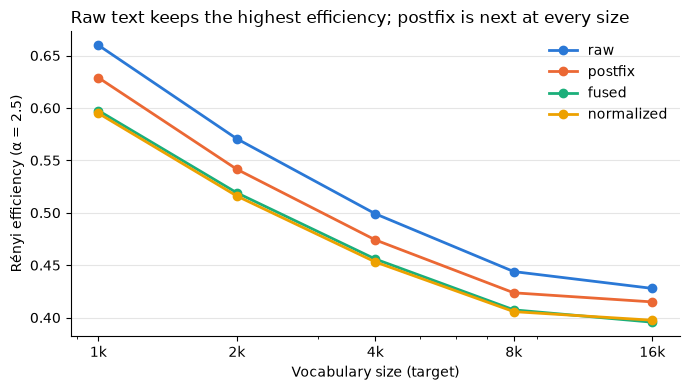

In [11]:
import matplotlib.pyplot as plt

COLORS = {"raw": "#2a78d6", "postfix": "#eb6834", "fused": "#1baf7a", "normalized": "#eda100"}
fig, ax = plt.subplots(figsize=(7, 4))
for name in order:
    d = df[df.layout == name]
    ax.plot(d.vocab_target, d.efficiency, marker="o", markersize=6, linewidth=2,
            color=COLORS[name], label=name)
ax.set_xscale("log")
ax.set_xticks(VOCAB_SIZES, [f"{v // 1000}k" for v in VOCAB_SIZES])
ax.set_xlabel("Vocabulary size (target)")
ax.set_ylabel("Rényi efficiency (α = 2.5)")
ax.set_title("Raw text keeps the highest efficiency; postfix is next at every size", loc="left")
ax.grid(axis="y", color="#e5e5e5")
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Conclusions
1. **The ranking is stable.** Efficiency: raw > postfix > fused ≈ normalized at every vocabulary size, so the result isn't an artefact of one setting.
2. **About half of the baseline entropy drop is the stray space token** (≈47% at 8k, ≈52% at 1k; Step 8).
3. **Postfix removes it for real.** Its Rényi entropy matches the "stray space removed" what-if at every size, so two independent methods agree.
4. **Postfix is the shortest normalized layout:** about +7.5% tokens over raw at 8k, against +15.9% (normalized) and +17.0% (fused).
5. **Limits:** one α (2.5), intrinsic measures only, and the 16k column isn't a true 16k. Whether any layout gives a better *model* needs the MT experiment.

---
# Part 2 — Does Rényi efficiency predict translation quality? (Dev BLEU vs efficiency)

This part reproduces the shape of Zouhar et al.'s Fig. 2 for Irish. For every Irish layout × vocabulary size it:

1. splits the parallel English–Irish corpus into **train / dev / test** (same split for every layout);
2. trains the Irish tokenizer on the **train split only**, and measures its Rényi efficiency there (the x-axis);
3. trains a small Transformer translation model **English → Irish** from scratch;
4. translates the dev set, converts the output back to normal Irish (undoing `[LEN]`/`[ECL]` markers), and scores it against the real Irish references with **sacreBLEU** (BLEU and chrF; the y-axis);
5. saves every run to `mt_results.csv` (re-running skips finished runs, so you can stop and resume).

**Extra packages (once, from the gaeilge_renyi_test folder):**
```
uv pip install torch sacrebleu
```
(For an NVIDIA GPU, install the CUDA build of torch from pytorch.org instead; the code uses the GPU automatically.)

**Runtime:** set by `EPOCHS`, `MT_VOCABS` and `MT_SEEDS` in Step 10.1. The first run prints minutes per model so you can plan the rest. A CPU laptop is fine for the default (12 models); the full grid with 3 seeds is an overnight or GPU job.

**Be aware:** 20,000 subtitle lines is very little data for translation, so BLEU will be low and noisy. Differences between layouts only mean something if they are larger than the spread across seeds.

## Step 10.1 — Settings

In [12]:
import math, random, time, re, warnings
import torch, torch.nn as nn
import sacrebleu
import pandas as pd
from tokenizers.decoders import ByteLevel as ByteLevelDecoder
from irish_mutations import remutate_word

warnings.filterwarnings("ignore", message=".*enable_nested_tensor.*")

MT_LAYOUTS = ["raw", "normalized", "fused", "postfix"]
MT_VOCABS  = [2000, 4000, 8000]     # Irish vocab sizes; add 1000 and 16000 for the full grid
MT_SEEDS   = [1]                    # add 2, 3 to get error bars (recommended before drawing conclusions)
EPOCHS     = 12                     # more epochs = better models, longer runs
EN_VOCAB   = 8000                   # English tokenizer size (fixed across all runs)
DEV_SIZE, TEST_SIZE = 1000, 1000
MAX_LEN    = 64                     # tokens per sentence (longer ones are truncated)
BATCH_SIZE = 64
RESULTS_FILE = Path("mt_results.csv")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE, "| CPU threads:", torch.get_num_threads())
print(f"Planned models: {len(MT_LAYOUTS) * len(MT_VOCABS) * len(MT_SEEDS)}")

Device: cpu | CPU threads: 8
Planned models: 12


## Step 10.2 — Parallel data and one fixed train/dev/test split
English and Irish files are line-aligned (line *i* of one translates line *i* of the other). Subtitles repeat a lot ("Yes.", "Thank you."), so two safeguards stop the model from being tested on sentences it has already seen:
1. exact duplicate sentence pairs are removed before splitting;
2. any dev/test sentence whose English line also occurs in train is dropped.

One random split (seed 0) is used for every layout, so all models see exactly the same sentences.

In [13]:
en_lines = (BASE_DIR / "OpenSubtitles.en-ga.en").read_text(encoding="utf-8").splitlines()
ga_layouts = {name: text.splitlines() for name, text in corpora.items()}   # from Step 4
assert all(len(v) == len(en_lines) for v in ga_layouts.values()), "files are not line-aligned"

seen, order_idx = set(), []
for i, pair in enumerate(zip(en_lines, ga_layouts["raw"])):   # 1. drop exact duplicate pairs
    if pair not in seen:
        seen.add(pair); order_idx.append(i)
print(f"{len(en_lines):,} pairs, {len(order_idx):,} after removing duplicates")

random.Random(0).shuffle(order_idx)
dev_idx   = order_idx[:DEV_SIZE]
test_idx  = order_idx[DEV_SIZE:DEV_SIZE + TEST_SIZE]       # kept untouched for a final evaluation later
train_idx = order_idx[DEV_SIZE + TEST_SIZE:]
train_en  = {en_lines[i] for i in train_idx}               # 2. no dev/test sentence seen in training
dev_idx   = [i for i in dev_idx if en_lines[i] not in train_en]
test_idx  = [i for i in test_idx if en_lines[i] not in train_en]
pick = lambda lines, idx: [lines[i] for i in idx]

dev_refs_raw = pick(ga_layouts["raw"], dev_idx)            # BLEU is always scored against real Irish
print(f"train {len(train_idx):,} | dev {len(dev_idx):,} | test {len(test_idx):,}")
print("EN:", en_lines[dev_idx[0]]); print("GA:", dev_refs_raw[0])

20,035 pairs, 17,536 after removing duplicates
train 15,536 | dev 977 | test 975
EN: Well?
GA: Bhuel?


## Step 10.3 — Tokenizers and Rényi efficiency (train split only)
Same BPE settings as the baseline, plus three control tokens the translation model needs (`<pad>`, `<s>`, `</s>`). Efficiency is measured on the train split, i.e. on exactly what the model is trained on.
`to_irish` turns model output in each layout back into normal Irish. A model can write things real Irish never contains (a marker with no word, or eclipsis on a word starting with *h*), so the conversion is forgiving: an impossible mutation keeps the plain root word, and stray markers are dropped.

In [14]:
CTRL = ["<pad>", "<s>", "</s>"]          # ids 0, 1, 2
PAD, BOS, EOS = 0, 1, 2

def make_tokenizer(lines, vocab_size, extra_special):
    tok = Tokenizer(BPE())
    tok.pre_tokenizer = ByteLevel(add_prefix_space=False)
    tok.decoder = ByteLevelDecoder()
    tok.train_from_iterator(lines, BpeTrainer(vocab_size=vocab_size, min_frequency=2,
                            special_tokens=CTRL + extra_special,
                            initial_alphabet=ByteLevel.alphabet(), show_progress=False))
    return tok

def efficiency_on(tok, lines):
    counts = Counter()
    for enc in tok.encode_batch(lines):
        counts.update(enc.ids)
    h = entropy(counts, 2.5)                           # Step 5
    return h / math.log2(tok.get_vocab_size()), sum(counts.values())

WORD = r"[A-Za-zÁÉÍÓÚáéíóú]+(?:-[A-Za-zÁÉÍÓÚáéíóú]+)*"
LAYOUT_RE = {                                         # marker + root, as written in each layout
    "normalized": (re.compile(rf"\[(LEN|ECL\^?)\] ({WORD})"), 1, 2),
    "fused":      (re.compile(rf"\[(LEN|ECL\^?)\]({WORD})"), 1, 2),
    "postfix":    (re.compile(rf"({WORD})\[(LEN|ECL\^?)\]"), 2, 1),
}
_LEFTOVER = re.compile(r"\[(LEN|ECL\^?)\]")

def safe_remutate(marker, root):
    try:
        return remutate_word(marker, root)                # baseline rule
    except ValueError:                                    # impossible mutation: keep the root
        return root

def to_irish(layout, s):
    if layout in LAYOUT_RE:
        rx, mi, ri = LAYOUT_RE[layout]
        s = rx.sub(lambda m: safe_remutate(m.group(mi), m.group(ri)), s)
    return re.sub(r"\s{2,}", " ", _LEFTOVER.sub("", s)).strip()

refs = [re.sub(r"\s{2,}", " ", x).strip() for x in pick(ga_layouts["raw"], dev_idx)]
for layout in MT_LAYOUTS:                                 # sanity check: real data converts back exactly
    assert [to_irish(layout, x) for x in pick(ga_layouts[layout], dev_idx)] == refs, layout
print("to_irish converts every layout back to the original Irish:", MT_LAYOUTS)

en_tok = make_tokenizer(pick(en_lines, train_idx), EN_VOCAB, [])
print("English tokenizer:", en_tok.get_vocab_size(), "tokens")

to_irish converts every layout back to the original Irish: ['raw', 'normalized', 'fused', 'postfix']
English tokenizer: 8000 tokens


## Step 10.4 — A small Transformer translation model (encoder–decoder)

In [15]:
class Translator(nn.Module):
    def __init__(self, src_vocab, tgt_vocab, d=256, heads=4, layers=3, ff=1024, dropout=0.1):
        super().__init__()
        self.d = d
        self.src_emb = nn.Embedding(src_vocab, d, padding_idx=PAD)
        self.tgt_emb = nn.Embedding(tgt_vocab, d, padding_idx=PAD)
        self.pos = nn.Embedding(MAX_LEN + 2, d)
        self.tf = nn.Transformer(d, heads, layers, layers, ff, dropout, batch_first=True, norm_first=True)
        self.out = nn.Linear(d, tgt_vocab)
        self.out.weight = self.tgt_emb.weight            # tie output layer to target embeddings
        for emb in (self.src_emb, self.tgt_emb):         # small init: embeddings are scaled by sqrt(d)
            nn.init.normal_(emb.weight, std=d ** -0.5)
        nn.init.normal_(self.pos.weight, std=0.02)

    def embed(self, emb, x):
        pos = torch.arange(x.size(1), device=x.device)
        return emb(x) * math.sqrt(self.d) + self.pos(pos)

    @staticmethod
    def causal_mask(n, device):                          # True = position may not be attended to
        return torch.triu(torch.ones(n, n, dtype=torch.bool, device=device), diagonal=1)

    def forward(self, src, tgt_in):
        mask = self.causal_mask(tgt_in.size(1), src.device)
        h = self.tf(self.embed(self.src_emb, src), self.embed(self.tgt_emb, tgt_in), tgt_mask=mask,
                    src_key_padding_mask=src == PAD, tgt_key_padding_mask=tgt_in == PAD,
                    memory_key_padding_mask=src == PAD)
        return self.out(h)

    @torch.no_grad()
    def translate(self, src):                            # greedy decoding
        memory = self.tf.encoder(self.embed(self.src_emb, src), src_key_padding_mask=src == PAD)
        ys = torch.full((src.size(0), 1), BOS, device=src.device)
        done = torch.zeros(src.size(0), dtype=torch.bool, device=src.device)
        for _ in range(MAX_LEN):
            mask = self.causal_mask(ys.size(1), src.device)
            h = self.tf.decoder(self.embed(self.tgt_emb, ys), memory, tgt_mask=mask,
                                memory_key_padding_mask=src == PAD)
            nxt = self.out(h[:, -1]).argmax(-1).masked_fill(done, PAD)
            ys = torch.cat([ys, nxt[:, None]], dim=1)
            done |= nxt == EOS
            if done.all():
                break
        return ys[:, 1:]

def encode_lines(tok, lines, add_bos_eos):
    out = []
    for enc in tok.encode_batch(lines):
        ids = enc.ids[:MAX_LEN]
        out.append([BOS] + ids + [EOS] if add_bos_eos else ids)
    return out

def batches(src, tgt, shuffle, rng):
    order = sorted(range(len(src)), key=lambda i: len(src[i]))         # similar lengths together
    chunks = [order[i:i + BATCH_SIZE] for i in range(0, len(order), BATCH_SIZE)]
    if shuffle:
        rng.shuffle(chunks)
    for ch in chunks:
        s = nn.utils.rnn.pad_sequence([torch.tensor(src[i]) for i in ch], batch_first=True, padding_value=PAD)
        t = None if tgt is None else nn.utils.rnn.pad_sequence(
            [torch.tensor(tgt[i]) for i in ch], batch_first=True, padding_value=PAD)
        yield ch, s.to(DEVICE), (None if t is None else t.to(DEVICE))

print("Model defined.")

Model defined.


## Step 10.5 — Train, translate, score (one model per layout × vocab × seed)
For each run: train for `EPOCHS`, keep the epoch with the lowest dev loss, translate the dev set, convert to normal Irish, and score with sacreBLEU. Finished runs are saved to `mt_results.csv` and skipped on re-run.

In [16]:
def run_mt(layout, vocab, seed):
    torch.manual_seed(seed); rng = random.Random(seed)
    ga = ga_layouts[layout]
    ga_tok = make_tokenizer(pick(ga, train_idx), vocab, [] if layout == "raw" else MARKERS)
    eff, train_tokens = efficiency_on(ga_tok, pick(ga, train_idx))

    src_tr = encode_lines(en_tok, pick(en_lines, train_idx), False)
    tgt_tr = encode_lines(ga_tok, pick(ga, train_idx), True)
    src_dv = encode_lines(en_tok, pick(en_lines, dev_idx), False)
    tgt_dv = encode_lines(ga_tok, pick(ga, dev_idx), True)

    model = Translator(en_tok.get_vocab_size(), ga_tok.get_vocab_size()).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=5e-4, betas=(0.9, 0.98), weight_decay=0.01)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min((s + 1) / 400, (400 / (s + 1)) ** 0.5))
    loss_fn = nn.CrossEntropyLoss(ignore_index=PAD, label_smoothing=0.1)

    best_loss, best_state = float("inf"), None
    for epoch in range(EPOCHS):
        model.train()
        for _, s, t in batches(src_tr, tgt_tr, True, rng):
            logits = model(s, t[:, :-1])
            loss = loss_fn(logits.reshape(-1, logits.size(-1)), t[:, 1:].reshape(-1))
            opt.zero_grad(); loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            opt.step(); sched.step()
        model.eval(); total, n = 0.0, 0
        with torch.no_grad():
            for _, s, t in batches(src_dv, tgt_dv, False, rng):
                logits = model(s, t[:, :-1])
                total += loss_fn(logits.reshape(-1, logits.size(-1)), t[:, 1:].reshape(-1)).item() * len(s); n += len(s)
        print(f"    epoch {epoch + 1}/{EPOCHS}: dev loss {total / n:.3f}", flush=True)
        if total / n < best_loss:
            best_loss = total / n
            best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}

    model.load_state_dict(best_state); model.eval()
    hyps = [""] * len(src_dv)
    for ch, s, _ in batches(src_dv, None, False, rng):
        for i, ids in zip(ch, model.translate(s).tolist()):
            ids = ids[:ids.index(EOS)] if EOS in ids else ids
            hyps[i] = to_irish(layout, ga_tok.decode([x for x in ids if x != PAD], skip_special_tokens=False))
    return {"layout": layout, "vocab_target": vocab, "seed": seed,
            "efficiency": eff, "train_tokens": train_tokens, "best_dev_loss": best_loss,
            "dev_bleu": sacrebleu.corpus_bleu(hyps, [dev_refs_raw]).score,
            "dev_chrf": sacrebleu.corpus_chrf(hyps, [dev_refs_raw]).score,
            "example": f"{pick(en_lines, dev_idx)[0]}  ->  {hyps[0]}"}

done = pd.read_csv(RESULTS_FILE) if RESULTS_FILE.exists() else pd.DataFrame()
finished = set() if done.empty else set(zip(done.layout, done.vocab_target, done.seed))
for seed in MT_SEEDS:
    for vocab in MT_VOCABS:
        for layout in MT_LAYOUTS:
            if (layout, vocab, seed) in finished:
                continue
            print(f"Training {layout} V={vocab} seed={seed} ...", flush=True)
            t0 = time.time()
            r = run_mt(layout, vocab, seed)
            r["minutes"] = (time.time() - t0) / 60
            done = pd.concat([done, pd.DataFrame([r])], ignore_index=True)
            done.to_csv(RESULTS_FILE, index=False)
            print(f"{layout:<10} V={vocab:>5} seed={seed}  eff={r['efficiency']:.4f}  "
                  f"BLEU={r['dev_bleu']:5.2f}  chrF={r['dev_chrf']:5.2f}  ({r['minutes']:.1f} min)")
print("All planned runs finished.")

Training raw V=2000 seed=1 ...
    epoch 1/12: dev loss 5.188
    epoch 2/12: dev loss 4.286
    epoch 3/12: dev loss 3.859
    epoch 4/12: dev loss 3.618
    epoch 5/12: dev loss 3.473
    epoch 6/12: dev loss 3.374
    epoch 7/12: dev loss 3.301
    epoch 8/12: dev loss 3.266
    epoch 9/12: dev loss 3.217
    epoch 10/12: dev loss 3.187
    epoch 11/12: dev loss 3.184
    epoch 12/12: dev loss 3.183
raw        V= 2000 seed=1  eff=0.5768  BLEU=19.94  chrF=34.83  (27.6 min)
Training normalized V=2000 seed=1 ...
    epoch 1/12: dev loss 4.763
    epoch 2/12: dev loss 3.991
    epoch 3/12: dev loss 3.613
    epoch 4/12: dev loss 3.397
    epoch 5/12: dev loss 3.261
    epoch 6/12: dev loss 3.163
    epoch 7/12: dev loss 3.112
    epoch 8/12: dev loss 3.060
    epoch 9/12: dev loss 3.035
    epoch 10/12: dev loss 2.997
    epoch 11/12: dev loss 2.991
    epoch 12/12: dev loss 2.979
normalized V= 2000 seed=1  eff=0.5155  BLEU=21.19  chrF=36.32  (82.1 min)
Training fused V=2000 seed=1 ...


## Step 10.6 — Results table and correlations
Averaged over seeds. Positive correlation = higher efficiency goes with better translation (the Zouhar et al. prediction). The per-vocab rows test the same question inside one vocabulary size.

In [18]:
res = pd.read_csv(RESULTS_FILE)
METRIC = "dev_bleu"                       # or "dev_chrf"
table = (res.groupby(["layout", "vocab_target"])
            .agg(efficiency=("efficiency", "mean"), score=(METRIC, "mean"),
                 score_sd=(METRIC, "std"), seeds=("seed", "count"))
            .reset_index().sort_values(["vocab_target", "efficiency"]))
display(table.round({"efficiency": 4, "score": 2, "score_sd": 2}))

def corr_row(d, label):
    row = {"subset": label, "n": len(d),
           "pearson_r": d.efficiency.corr(d.score),                           # Pearson
           "spearman_rho": d.efficiency.rank().corr(d.score.rank())}          # Spearman = Pearson on ranks
    try:                                                                      # p-values only if scipy is installed
        from scipy import stats
        row["pearson_p"] = stats.pearsonr(d.efficiency, d.score)[1]
        row["spearman_p"] = stats.spearmanr(d.efficiency, d.score)[1]
    except ImportError:
        pass
    return row

corr = pd.DataFrame([corr_row(table, "all settings")] +
                    [corr_row(g, f"vocab {v // 1000}k") for v, g in table.groupby("vocab_target") if len(g) >= 3])
display(corr.round(3))
print("Example dev translation per run:")
for _, r in res.iterrows():
    print(f"  {r.layout:<10} V={r.vocab_target:>5}: {r.example}")

,layout,vocab_target,efficiency,score,score_sd,seeds
3,normalized,2000,0.5155,21.19,NaN,1
0,fused,2000,0.5186,20.58,NaN,1
6,postfix,2000,0.5437,21.27,NaN,1
9,raw,2000,0.5768,19.94,NaN,1
4,normalized,4000,0.4528,20.29,NaN,1
1,fused,4000,0.4557,19.84,NaN,1
7,postfix,4000,0.4760,21.30,NaN,1
10,raw,4000,0.5047,20.29,NaN,1
5,normalized,8000,0.4050,20.60,NaN,1
2,fused,8000,0.4070,19.08,NaN,1


,subset,n,pearson_r,spearman_rho
0,all settings,12,0.257,0.133
1,vocab 2k,4,-0.666,-0.400
2,vocab 4k,4,0.250,0.000
3,vocab 8k,4,0.760,0.400


Example dev translation per run:
  raw        V= 2000: Well?  ->  Bhuel?
  normalized V= 2000: Well?  ->  Bhuel?
  fused      V= 2000: Well?  ->  Bhuel?
  postfix    V= 2000: Well?  ->  Bhuel?
  raw        V= 4000: Well?  ->  Bhuel?
  normalized V= 4000: Well?  ->  Bhuel?
  fused      V= 4000: Well?  ->  Bhuel?
  postfix    V= 4000: Well?  ->  Bhuel?
  raw        V= 8000: Well?  ->  Bhuel?
  normalized V= 8000: Well?  ->  Bhuel?
  fused      V= 8000: Well?  ->  Bhuel?
  postfix    V= 8000: Well?  ->  Bhuel?


## Step 10.7 — Chart: dev score vs Rényi efficiency.

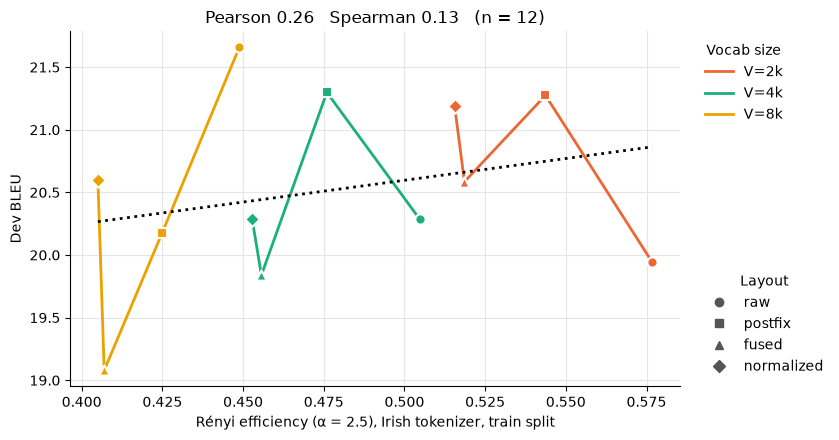

In [19]:
import numpy as np
from matplotlib.lines import Line2D

V_COLORS = {1000: "#2a78d6", 2000: "#eb6834", 4000: "#1baf7a", 8000: "#eda100", 16000: "#e87ba4"}
L_MARKERS = {"raw": "o", "postfix": "s", "fused": "^", "normalized": "D"}

fig, ax = plt.subplots(figsize=(8.5, 4.5))
for v, g in table.groupby("vocab_target"):
    g = g.sort_values("efficiency")
    c = V_COLORS.get(v, "#888888")
    ax.plot(g.efficiency, g.score, color=c, linewidth=2, label=f"V={v // 1000}k")
    if g.score_sd.notna().any():
        ax.errorbar(g.efficiency, g.score, yerr=g.score_sd, fmt="none", ecolor=c, elinewidth=1, capsize=3)
    for _, r in g.iterrows():
        ax.scatter(r.efficiency, r.score, marker=L_MARKERS.get(r.layout, "o"), s=55,
                   color=c, edgecolor="white", linewidth=1.5, zorder=3)
if len(table) >= 3:
    slope, intercept = np.polyfit(table.efficiency, table.score, 1)
    xs = np.linspace(table.efficiency.min(), table.efficiency.max(), 50)
    ax.plot(xs, slope * xs + intercept, linestyle=":", color="black", linewidth=2)

overall = corr.iloc[0]
ax.set_title(f"Pearson {overall.pearson_r:.2f}   Spearman {overall.spearman_rho:.2f}   (n = {int(overall.n)})")
ax.set_xlabel("Rényi efficiency (α = 2.5), Irish tokenizer, train split")
ax.set_ylabel("Dev BLEU" if METRIC == "dev_bleu" else "Dev chrF")
ax.grid(color="#e5e5e5"); ax.set_axisbelow(True)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
leg1 = ax.legend(loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False, title="Vocab size")
ax.add_artist(leg1)
ax.legend(handles=[Line2D([], [], marker=m, linestyle="", color="#555555", label=k) for k, m in L_MARKERS.items()],
          loc="lower left", bbox_to_anchor=(1.02, 0), frameon=False, title="Layout")
plt.tight_layout(); plt.show()